# Market risk: VaR and Expected Shortfall backtesting

**Objective:** compare four models of 1-day Value at Risk at 99% (historical simulation, normal, EWMA and GARCH(1,1) with Student-t) for stock indices of the US, France and Europe and for two Colombian stocks, and check which model passes the backtests that a regulator would ask: Kupiec, Christoffersen and the Basel traffic light.

**Data:** daily adjusted prices from Yahoo Finance: S&P 500, CAC 40, Euro Stoxx 50, Ecopetrol (EC) and Bancolombia (CIB) ADRs, from 2012.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `yfinance`, `scipy` and `arch`.

## Part 1. Libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy import stats
from arch import arch_model

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
activos = {"^GSPC": "S&P 500", "^FCHI": "CAC 40", "^STOXX50E": "Euro Stoxx 50", "EC": "Ecopetrol", "CIB": "Bancolombia"}
precios = yf.download(list(activos), start="2012-01-01", auto_adjust=True, progress=False)["Close"].rename(columns=activos)
precios.to_csv("data/prices.csv")
# log returns of each asset with its own trading days
ret = pd.concat({c: np.log(precios[c].dropna()).diff().dropna() for c in precios.columns}, axis=1)
print("From", ret.index.min().date(), "to", ret.index.max().date())

From 2012-01-04 to 2026-10-20


## Part 2. Are the returns normal?

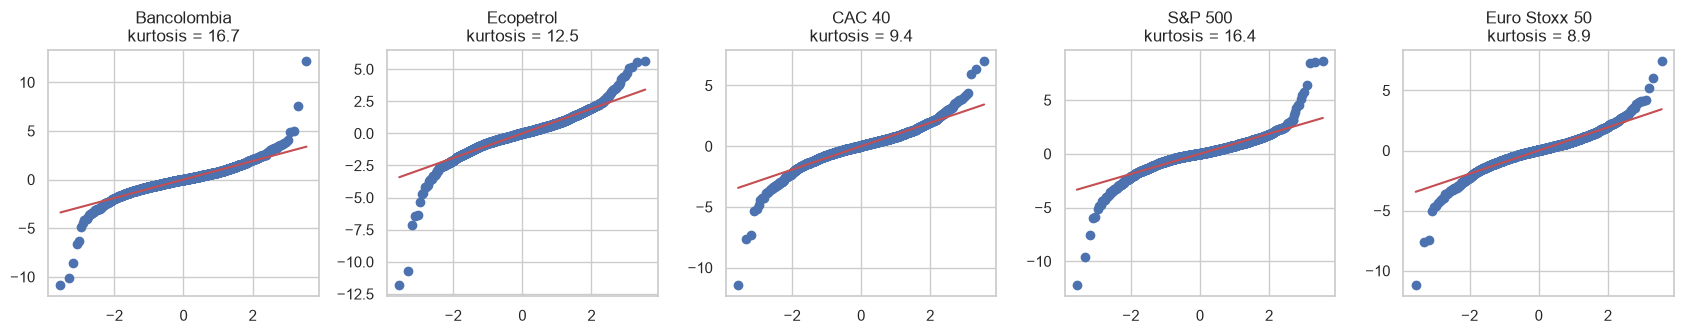

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.5))
for ax, c in zip(axes, ret.columns):
    r = ret[c].dropna()
    stats.probplot((r - r.mean()) / r.std(), dist="norm", plot=ax)
    ax.set_title(f"{c}\nkurtosis = {stats.kurtosis(r):.1f}")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig("figures/qq_plots.png", bbox_inches="tight")
plt.show()

All the series have fat tails: the points go away from the line in the extremes and the excess kurtosis is between 9 and 17 (a normal distribution has 0). So a normal VaR will underestimate the big losses.

## Part 3. The four VaR models

We use a rolling window of 500 days and every day we forecast the VaR of the next day (without using future information). VaR and ES are reported as positive numbers (losses).

- **HS:** the 1% quantile of the last 500 returns
- **Normal:** mean and standard deviation of the last 500 days
- **EWMA:** RiskMetrics variance with lambda = 0.94
- **GARCH-t:** GARCH(1,1) with Student-t errors, estimated again every 20 days

In [4]:
alpha, ventana = 0.01, 500
z = stats.norm.ppf(alpha)

def modelos(r):
    x = r.values
    n = len(x)
    res = pd.DataFrame(index=r.index, columns=["HS", "Normal", "EWMA", "GARCH-t", "ES_HS", "ES_Normal", "ES_GARCH-t"], dtype=float)
    ewma = np.zeros(n)
    ewma[0] = x[:ventana].var()
    for t in range(1, n):
        ewma[t] = 0.94 * ewma[t - 1] + 0.06 * x[t - 1] ** 2
    for t in range(ventana, n):
        w = x[t - ventana:t]
        q = np.quantile(w, alpha)
        res.iloc[t, 0] = -q
        res.iloc[t, 4] = -w[w <= q].mean()
        res.iloc[t, 1] = -(w.mean() + z * w.std())
        res.iloc[t, 5] = -(w.mean() - w.std() * stats.norm.pdf(z) / alpha)
        res.iloc[t, 2] = -z * np.sqrt(ewma[t])
        if (t - ventana) % 20 == 0:
            g = arch_model(w * 100, vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
            mu, om, a1, b1, nu = g.params["mu"], g.params["omega"], g.params["alpha[1]"], g.params["beta[1]"], g.params["nu"]
            s2 = g.conditional_volatility[-1] ** 2
            qt = stats.t.ppf(alpha, nu) * np.sqrt((nu - 2) / nu)
            es_t = stats.t.pdf(stats.t.ppf(alpha, nu), nu) / alpha * (nu + stats.t.ppf(alpha, nu) ** 2) / (nu - 1) * np.sqrt((nu - 2) / nu)
        # the GARCH variance of tomorrow, with the return of today
        s2 = om + a1 * (x[t - 1] * 100 - mu) ** 2 + b1 * s2
        res.iloc[t, 3] = -(mu + qt * np.sqrt(s2)) / 100
        res.iloc[t, 6] = (-mu + es_t * np.sqrt(s2)) / 100
    res["ret"] = x
    return res.iloc[ventana:]

resultados = {}
for c in ret.columns:
    resultados[c] = modelos(ret[c].dropna())
    print(c, "done")

Bancolombia done


Ecopetrol done


CAC 40 done


S&P 500 done


Euro Stoxx 50 done


## Part 4. Backtesting

- **Kupiec:** is the number of exceptions consistent with 1%?
- **Christoffersen:** are the exceptions independent, or do they come in clusters?
- **Basel traffic light:** exceptions in the last 250 days (0-4 green, 5-9 yellow, 10 or more red)

In [5]:
def kupiec(hits):
    n, x = len(hits), hits.sum()
    p = x / n
    lr = -2 * ((n - x) * np.log(1 - alpha) + x * np.log(alpha) - (n - x) * np.log(1 - p) - x * np.log(p))
    return 1 - stats.chi2.cdf(lr, 1)

def christoffersen(hits):
    h = hits.astype(int)
    n00 = ((h[:-1] == 0) & (h[1:] == 0)).sum()
    n01 = ((h[:-1] == 0) & (h[1:] == 1)).sum()
    n10 = ((h[:-1] == 1) & (h[1:] == 0)).sum()
    n11 = ((h[:-1] == 1) & (h[1:] == 1)).sum()
    p01, p11 = n01 / (n00 + n01), n11 / max(n10 + n11, 1)
    p = (n01 + n11) / (n00 + n01 + n10 + n11)
    l0 = (n00 + n10) * np.log(1 - p) + (n01 + n11) * np.log(p)
    l1 = n00 * np.log(1 - p01) + n01 * np.log(p01) + n10 * np.log(1 - p11) + (n11 * np.log(p11) if n11 > 0 else 0)
    return 1 - stats.chi2.cdf(-2 * (l0 - l1), 1)

filas = []
for c, d in resultados.items():
    for m in ["HS", "Normal", "EWMA", "GARCH-t"]:
        hits = (d["ret"] < -d[m]).values
        ult = hits[-250:].sum()
        zona = "green" if ult <= 4 else ("yellow" if ult <= 9 else "red")
        filas.append([c, m, round(hits.mean() * 100, 2), round(kupiec(hits), 3), round(christoffersen(hits), 3), ult, zona])
tabla = pd.DataFrame(filas, columns=["asset", "model", "exceptions_%", "kupiec_p", "christoffersen_p", "last_250", "basel"])
tabla.to_csv("data/backtest_summary.csv", index=False)
tabla

,asset,model,exceptions_%,kupiec_p,christoffersen_p,last_250,basel
0,Bancolombia,HS,1.49,0.009,0.006,3,green
1,Bancolombia,Normal,1.93,0.000,0.000,4,green
2,Bancolombia,EWMA,1.58,0.002,0.254,3,green
3,Bancolombia,GARCH-t,1.09,0.625,0.398,3,green
4,Ecopetrol,HS,1.37,0.048,0.003,2,green
5,Ecopetrol,Normal,2.17,0.000,0.000,4,green
6,Ecopetrol,EWMA,1.99,0.000,0.543,1,green
7,Ecopetrol,GARCH-t,1.34,0.069,0.606,2,green
8,CAC 40,HS,1.49,0.008,0.000,1,green
9,CAC 40,Normal,2.41,0.000,0.000,2,green


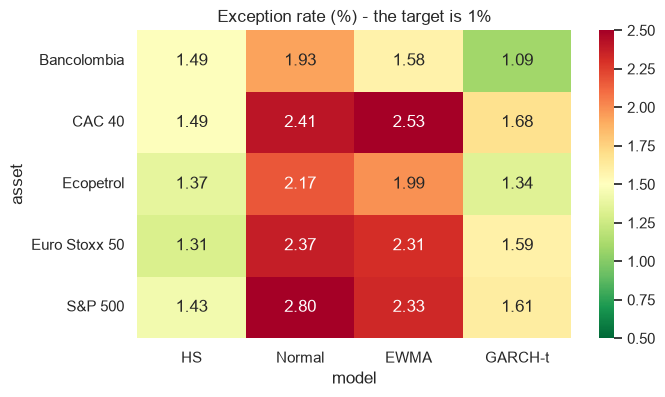

model
EWMA       2.15
GARCH-t    1.46
HS         1.42
Normal     2.34
Name: exceptions_%, dtype: float64


In [6]:
pivote = tabla.pivot(index="asset", columns="model", values="exceptions_%")[["HS", "Normal", "EWMA", "GARCH-t"]]
plt.figure(figsize=(7, 4))
sns.heatmap(pivote, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=0.5, vmax=2.5)
plt.title("Exception rate (%) - the target is 1%")
plt.savefig("figures/exception_rates.png", bbox_inches="tight")
plt.show()
print(tabla.groupby("model")["exceptions_%"].mean().round(2))

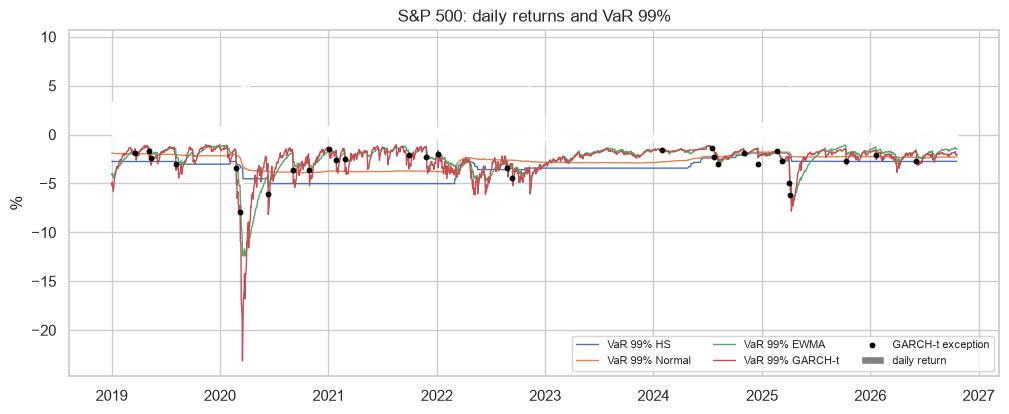

In [7]:
d = resultados["S&P 500"].loc["2019":]
plt.figure(figsize=(12, 4.5))
plt.bar(d.index, d["ret"] * 100, color="grey", width=1.5, label="daily return")
for m in ["HS", "Normal", "EWMA", "GARCH-t"]:
    plt.plot(d.index, -d[m] * 100, lw=1, label="VaR 99% " + m)
exc = d[d["ret"] < -d["GARCH-t"]]
plt.scatter(exc.index, exc["ret"] * 100, color="black", s=10, zorder=5, label="GARCH-t exception")
plt.title("S&P 500: daily returns and VaR 99%")
plt.ylabel("%")
plt.legend(ncol=3, fontsize=8)
plt.savefig("figures/sp500_var.png", bbox_inches="tight")
plt.show()

## Part 5. Expected Shortfall

When the loss is bigger than the VaR, how big is it compared to the ES that the model predicted? A ratio close to 1 means the model gets the size of the tail right.

In [8]:
filas = []
for c, d in resultados.items():
    for m in ["HS", "Normal", "GARCH-t"]:
        mal = d["ret"] < -d[m]
        filas.append([c, m, round((-d.loc[mal, "ret"] / d.loc[mal, "ES_" + m]).mean(), 2)])
pd.DataFrame(filas, columns=["asset", "model", "loss / ES"]).pivot(index="asset", columns="model", values="loss / ES")

model,GARCH-t,HS,Normal
asset,,,
Bancolombia,1.07,1.11,1.33
CAC 40,1.01,1.06,1.28
Ecopetrol,1.10,1.09,1.32
Euro Stoxx 50,1.03,1.10,1.28
S&P 500,1.10,1.12,1.33


## Conclusions

- The normal VaR fails in every asset: it has between 1.9% and 2.8% of exceptions when the target is 1%, and in the days it fails the real loss is around 30% bigger than its ES.
- No model is perfect at 99%. Historical simulation gets the closest number of exceptions for the indices, but its exceptions come in clusters (Christoffersen rejects): the 500-day window reacts too slowly when the volatility changes, like in 2020 or 2022.
- GARCH with Student-t is the best model for the Colombian stocks: it is the only model that passes both Kupiec and Christoffersen at 5% for Bancolombia and Ecopetrol, and its ES is almost exactly the size of the real losses (ratio between 1.01 and 1.10).